In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
def metriche(c):          # c = matrice (finestre x utenti) con il numero di commenti
    att = c > 0
    pers = att[:-1] & att[1:]                       # attivo in k e in k+1
    ricambio = 1 - pers.sum(1) / att[1:].sum(1)
    quota = (c[1:] * pers).sum(1) / c[1:].sum(1)
    return ricambio, quota

In [3]:
df_moltbook         = pd.read_pickle('df_moltbook_interactions.pkl')
df_reddit           = pd.read_pickle('df_reddit_interactions.pkl')

In [4]:
rng = np.random.default_rng(0)
DEL = {"[deleted]", "[removed]", "unknown"}

inizio = pd.Timestamp("2026-05-01", tz="UTC")
fine = pd.Timestamp("2026-08-01", tz="UTC")
n_giorni = (fine - inizio).days

In [5]:
d = df_reddit[(df_reddit["community"] == "philosophy")
          & df_reddit["mittente"].notna() & ~df_reddit["mittente"].isin(DEL)
          & (df_reddit["t"] >= inizio) & (df_reddit["t"] < fine)].copy()
d["giorno"] = (d["t"] - inizio).dt.days

In [6]:
lam = d["mittente"].value_counts() / n_giorni        # commenti al giorno per utente

righe_r = []
for w in [1, 3, 7, 14]:
    n_fin = n_giorni // w                            # solo finestre complete
    dd = d[d["giorno"] // w < n_fin]

    # 1. dati reali
    dati = pd.crosstab(dd["giorno"] // w, dd["mittente"]).reindex(range(n_fin), fill_value=0)

    # 2. modello di Poisson
    poisson = rng.poisson(lam.values * w, size=(n_fin, len(lam)))

    # 3. autori rimescolati tra i commenti (stessi tempi, stesso numero di commenti per autore)
    mix = dd.assign(mittente=rng.permutation(dd["mittente"].values))
    mix = pd.crosstab(mix["giorno"] // w, mix["mittente"]).reindex(range(n_fin), fill_value=0)

    for nome, c in [("dati", dati.to_numpy()), ("poisson", poisson), ("rimescolato", mix.to_numpy())]:
        ricambio, quota = metriche(c)
        for k in range(len(ricambio)):
            righe_r.append({"finestra_giorni": w, "versione": nome, "finestra": k + 1,
                          "ricambio": ricambio[k], "quota_persistenti": quota[k]})

righe_r = pd.DataFrame(righe_r)

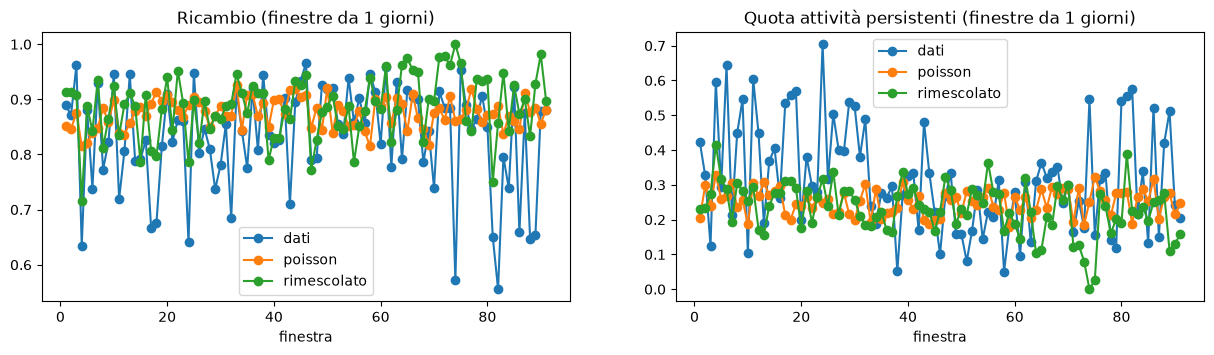

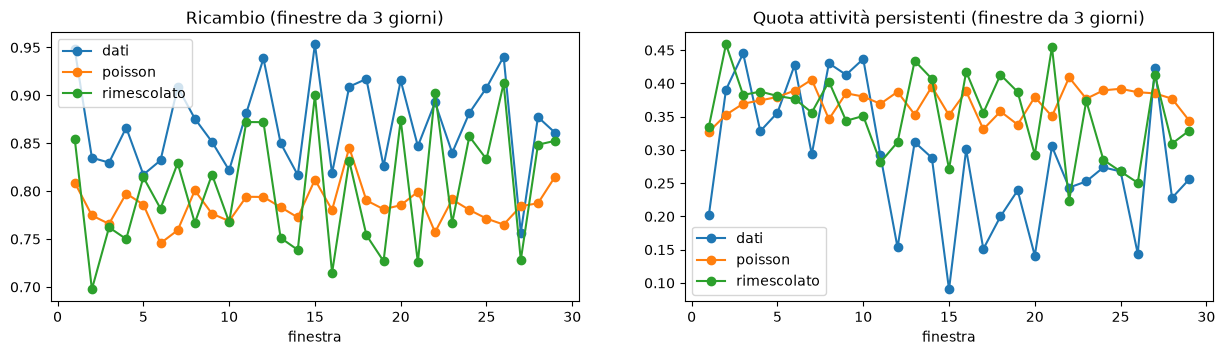

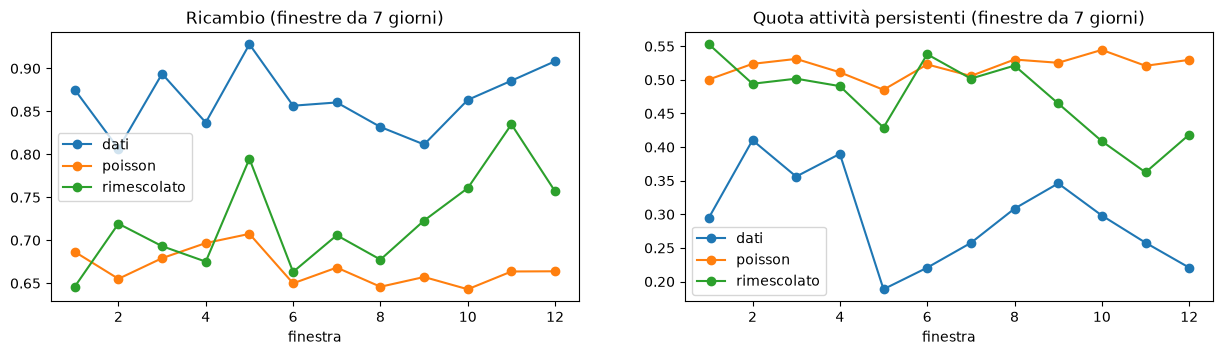

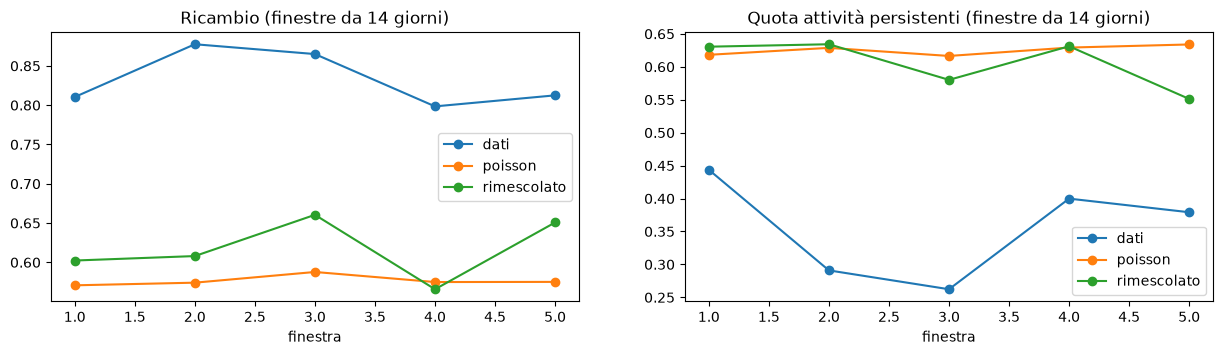

In [7]:
for w in [1, 3, 7, 14]:
    t = righe_r[righe_r["finestra_giorni"] == w]

    fig, ax = plt.subplots(1, 2, figsize=(15, 3.5))

    for versione in ["dati", "poisson", "rimescolato"]:
        v = t[t["versione"] == versione]
        ax[0].plot(v["finestra"], v["ricambio"], marker="o", label=versione)
        ax[1].plot(v["finestra"], v["quota_persistenti"], marker="o", label=versione)

    ax[0].set_title(f"Ricambio (finestre da {w} giorni)")
    ax[1].set_title(f"Quota attività persistenti (finestre da {w} giorni)")
    for a in ax:
        a.set_xlabel("finestra")
        a.legend()

    plt.show()

In [8]:
m = df_moltbook[(df_moltbook["community"] == "philosophy")
          & df_moltbook["mittente"].notna() & ~df_moltbook["mittente"].isin(DEL)
          & (df_moltbook["t"] >= inizio) & (df_moltbook["t"] < fine)].copy()
m["giorno"] = (m["t"] - inizio).dt.days

In [9]:
lam = m["mittente"].value_counts() / n_giorni        # commenti al giorno per utente

righe_m = []
for w in [1, 3, 7, 14]:
    n_fin = n_giorni // w                            # solo finestre complete
    dd = m[m["giorno"] // w < n_fin]

    # 1. dati reali
    dati = pd.crosstab(dd["giorno"] // w, dd["mittente"]).reindex(range(n_fin), fill_value=0)

    # 2. modello di Poisson
    poisson = rng.poisson(lam.values * w, size=(n_fin, len(lam)))

    # 3. autori rimescolati tra i commenti (stessi tempi, stesso numero di commenti per autore)
    mix = dd.assign(mittente=rng.permutation(dd["mittente"].values))
    mix = pd.crosstab(mix["giorno"] // w, mix["mittente"]).reindex(range(n_fin), fill_value=0)

    for nome, c in [("dati", dati.to_numpy()), ("poisson", poisson), ("rimescolato", mix.to_numpy())]:
        ricambio, quota = metriche(c)
        for k in range(len(ricambio)):
            righe_m.append({"finestra_giorni": w, "versione": nome, "finestra": k + 1,
                          "ricambio": ricambio[k], "quota_persistenti": quota[k]})

righe_m = pd.DataFrame(righe_m)

/tmp/ipykernel_7266/351113356.py:4: RuntimeWarning: invalid value encountered in divide
  ricambio = 1 - pers.sum(1) / att[1:].sum(1)
/tmp/ipykernel_7266/351113356.py:5: RuntimeWarning: invalid value encountered in divide
  quota = (c[1:] * pers).sum(1) / c[1:].sum(1)


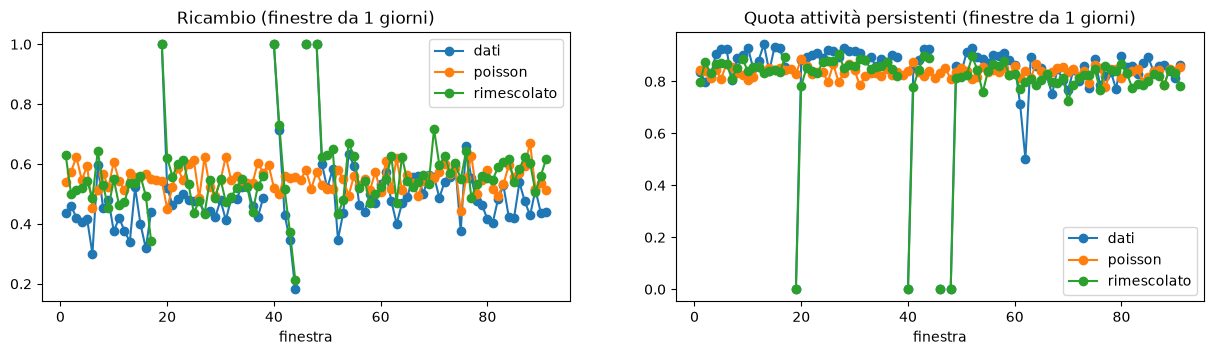

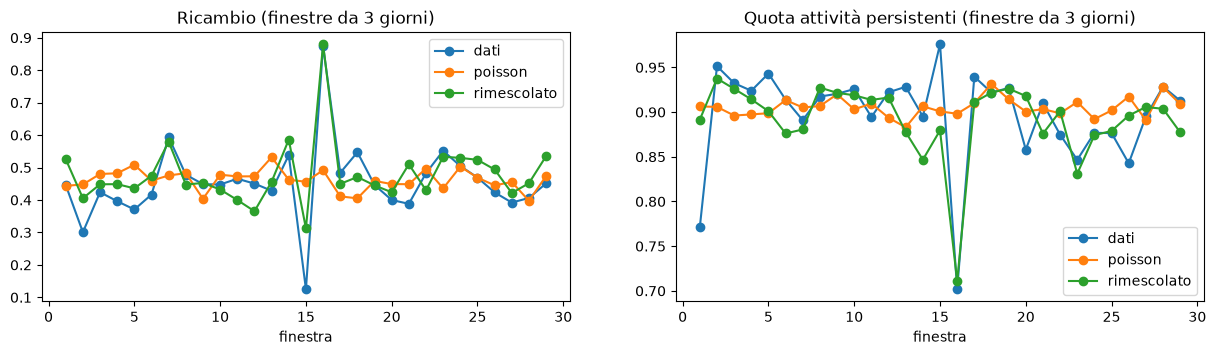

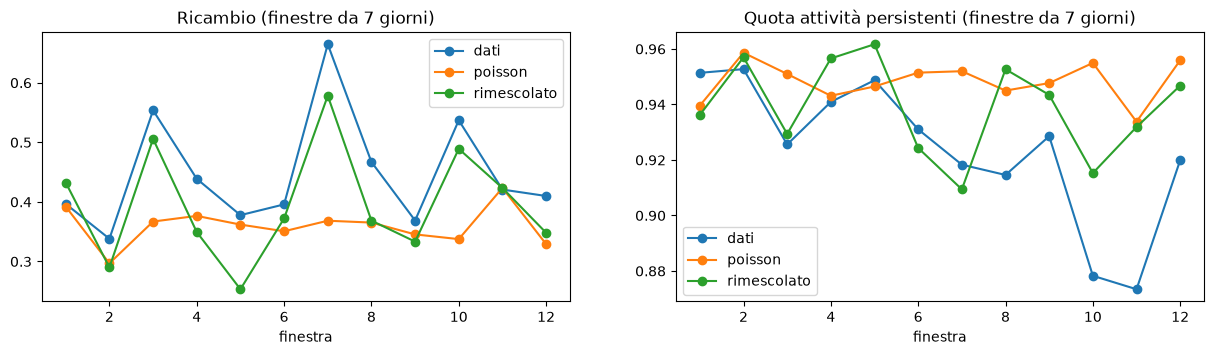

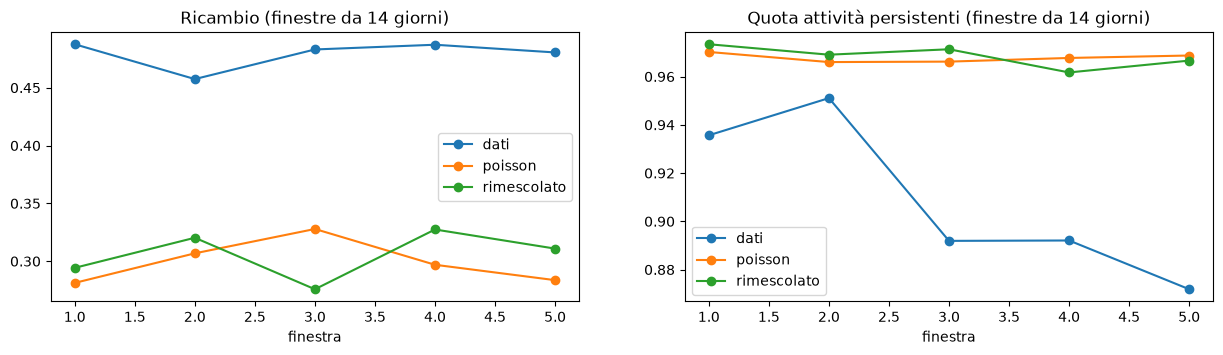

In [10]:
for w in [1, 3, 7, 14]:
    t = righe_m[righe_m["finestra_giorni"] == w]

    fig, ax = plt.subplots(1, 2, figsize=(15, 3.5))

    for versione in ["dati", "poisson", "rimescolato"]:
        v = t[t["versione"] == versione]
        ax[0].plot(v["finestra"], v["ricambio"], marker="o", label=versione)
        ax[1].plot(v["finestra"], v["quota_persistenti"], marker="o", label=versione)

    ax[0].set_title(f"Ricambio (finestre da {w} giorni)")
    ax[1].set_title(f"Quota attività persistenti (finestre da {w} giorni)")
    for a in ax:
        a.set_xlabel("finestra")
        a.legend()

    plt.show()